(sec-6)=
# 6. Benchmark final

En esta sección se reúnen los resultados en la tabla de la plantilla A.2, se ordenan los modelos por desempeño y costo, se aplican las pruebas de hipótesis de las tres RQ confirmatorias, se estima el techo de desempeño y la incertidumbre, y se discuten los resultados. Las observaciones pareadas son las R semillas, que comparten partición, prueba y orden de los datos entre modelos.

(sec-6-1)=
## 6.1 Comparación tabular

In [59]:
W_PRU_PAREADO = AN.pesos_bootstrap(NB_PRU, semilla=7)
F1_BOOT = {m: np.mean([AN.f1_desde_conteos(W_PRU_PAREADO @ CONF_BLOQUES[f"{i}|eva"]) for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]], 0) for m in ORDEN}
rangos = pd.Series(E.rangos_medios(F1P[ORDEN].to_numpy()), index=ORDEN)
ece_m = METRICAS.groupby("modelo")["prueba ECE"].mean()
tabla_a2 = pd.DataFrame({"Grupo": [("Trivial" if m == "Trivial" else "Clásico" if m in ("LightGBM", "Logística") else "Base E1" if m in CONFIG["modelos"]["base_e1"] else "Top 10") for m in ORDEN],
                         "F1 macro (media ± DE)": [f"{num(F1P[m].mean(), 4)} ± {num(F1P[m].std(), 4)}" for m in ORDEN],
                         "IC 95 % (bootstrap por bloques)": [intervalo(E.ic_percentil(F1_BOOT[m])) for m in ORDEN], "ECE": [ece_m[m] for m in ORDEN],
                         "Robustez (índice)": [ROBUSTEZ.loc[m, "Índice medio"] if m in ROBUSTEZ.index else np.nan for m in ORDEN],
                         "Parámetros": [costo.loc[m, "Parámetros"] for m in ORDEN], "FLOPs": [costo.loc[m, "FLOPs"] for m in ORDEN],
                         "Entrenamiento (min por corrida)": [costo.loc[m, "Minutos"] for m in ORDEN], "Latencia (ms)": [costo.loc[m, "ms_por_muestra"] for m in ORDEN],
                         "Rango promedio": [rangos[m] for m in ORDEN]}, index=ORDEN)
TABLA_A2 = tabla_a2.sort_values("Rango promedio")
TABLA_A2.to_csv(RESULTADOS / "tabla_benchmark.csv", encoding="utf-8-sig", index_label="Modelo")
tabla(TABLA_A2.reset_index(names="Modelo"), {"ECE": "{:.4f}", "Robustez (índice)": "{:.3f}", "Parámetros": "{:,.0f}", "FLOPs": "{:,.0f}", "Entrenamiento (min por corrida)": "{:.2f}",
                                            "Latencia (ms)": "{:.3f}", "Rango promedio": "{:.2f}"})
primero = TABLA_A2.index[0]
IC_TABLA = {m: E.ic_percentil(F1_BOOT[m]) for m in ORDEN}
ancho_ic = np.median([IC_TABLA[m][1] - IC_TABLA[m][0] for m in ORDEN if m != "Trivial"])
solapan = [m for m in ORDEN if m not in (primero, "Trivial") and IC_TABLA[m][1] >= IC_TABLA[primero][0]]
supera_e1 = [m for m in PROFUNDOS if F1P[m].mean() >= 0.8775]
interpretar(f'''**Interpretación.** Por rango promedio, el primer lugar es para {primero}, con F1 macro de {num(F1P[primero].mean(), 4)} e IC por bloques de {intervalo(IC_TABLA[primero])}, seguido de {enumerar(TABLA_A2.index[1:4])}. El baseline del Entregable 1, CNN 1D, queda en el puesto {list(TABLA_A2.index).index("CNN 1D") + 1} con {num(F1P["CNN 1D"].mean(), 4)}{"" if primero == "LightGBM" else f", LightGBM en el {list(TABLA_A2.index).index('LightGBM') + 1} con {num(F1P['LightGBM'].mean(), 4)}"} y el trivial, último, con {num(F1P["Trivial"].mean(), 4)}. {("Entre los modelos profundos, " + ("supera" if len(supera_e1) == 1 else "superan") + " el umbral de mejora que fijó el Entregable 1, 0,8775, " + enumerar(supera_e1)) if supera_e1 else "Ningún modelo profundo supera el umbral de mejora que fijó el Entregable 1, 0,8775"}.

Hay que tener en cuenta que los intervalos por bloques tienen un ancho mediano de {num(ancho_ic, 3)} y que el de {primero} se solapa con el de {len(solapan)} de los otros {len(ORDEN) - 2} modelos no triviales, porque reflejan cuánto cambia el F1 según qué series caigan en la prueba. Es decir, la tabla ordena, pero no decide: si una diferencia es real se resuelve con las pruebas pareadas de la sección 6.3, que comparan los modelos sobre las mismas series y semillas.

Por tal motivo, se mantiene la tabla como resumen y la conclusión se apoya en los contrastes preregistrados.''')

Modelo,Grupo,F1 macro (media ± DE),IC 95 % (bootstrap por bloques),ECE,Robustez (índice),Parámetros,FLOPs,Entrenamiento (min por corrida),Latencia (ms),Rango promedio
LightGBM,Clásico,"0,8748 ± 0,0012","[0,7464; 0,9516]","0,0356","0,725",32 916,,"0,24","1,585","1,70"
CNN-LSTM,Top 10,"0,8626 ± 0,0188","[0,7346; 0,9297]","0,0467","0,768",46 213,924 288,"3,39","3,206","4,40"
Autoencoder,Top 10,"0,8591 ± 0,0095","[0,7365; 0,9210]","0,0485","0,790",19 093,19 072,"0,59","0,298","5,85"
Transformer,Top 10,"0,8576 ± 0,0127","[0,7319; 0,9193]","0,0484","0,787",3 381,22 144,"0,86","1,348","6,15"
CNN 1D,Base E1,"0,8584 ± 0,0050","[0,7345; 0,9242]","0,0492","0,810",39 493,265 856,"1,97","1,594","6,20"
DNN,Base E1,"0,8577 ± 0,0084","[0,7303; 0,9226]","0,0499","0,803",12 677,24 896,"0,68","0,400","6,30"
DBN,Top 10,"0,8569 ± 0,0062","[0,7316; 0,9262]","0,0522","0,694",9 733,19 072,"1,84","0,362","6,65"
ResNet,Top 10,"0,8510 ± 0,0126","[0,7284; 0,9131]","0,0540","0,815",14 245,26 944,"0,81","0,890","8,10"
BiLSTM,Top 10,"0,8457 ± 0,0238","[0,7224; 0,9127]","0,0506","0,803",530 693,16 812 544,"33,87","10,539","8,15"
KAN,Top 10,"0,8488 ± 0,0124","[0,7276; 0,9160]","0,0563","0,774",4 845,9 376,"1,61","1,477","8,90"


**Interpretación.** Por rango promedio, el primer lugar es para LightGBM, con F1 macro de 0,8748 e IC por bloques de [0,7464; 0,9516], seguido de CNN-LSTM, Autoencoder y Transformer. El baseline del Entregable 1, CNN 1D, queda en el puesto 5 con 0,8584 y el trivial, último, con 0,0698. Ningún modelo profundo supera el umbral de mejora que fijó el Entregable 1, 0,8775.

Hay que tener en cuenta que los intervalos por bloques tienen un ancho mediano de 0,191 y que el de LightGBM se solapa con el de 14 de los otros 14 modelos no triviales, porque reflejan cuánto cambia el F1 según qué series caigan en la prueba. Es decir, la tabla ordena, pero no decide: si una diferencia es real se resuelve con las pruebas pareadas de la sección {ref}`6.3 <sec-6-3>`, que comparan los modelos sobre las mismas series y semillas.

Por tal motivo, se mantiene la tabla como resumen y la conclusión se apoya en los contrastes preregistrados.

(sec-6-2)=
## 6.2 Ranking y eficiencia

Se ordenan los modelos por su rango promedio sobre las semillas y se identifica la frontera de Pareto entre el F1 macro y cada medida de costo: un modelo es no dominado si ningún otro tiene mayor F1 con menor o igual costo. El costo por unidad de mejora relaciona el incremento de F1 frente al mejor baseline no profundo con el incremento de costo, $\eta_k = (s_k - s_{base}) / (c_k - c_{base})$, con su intervalo por *bootstrap* por bloques.

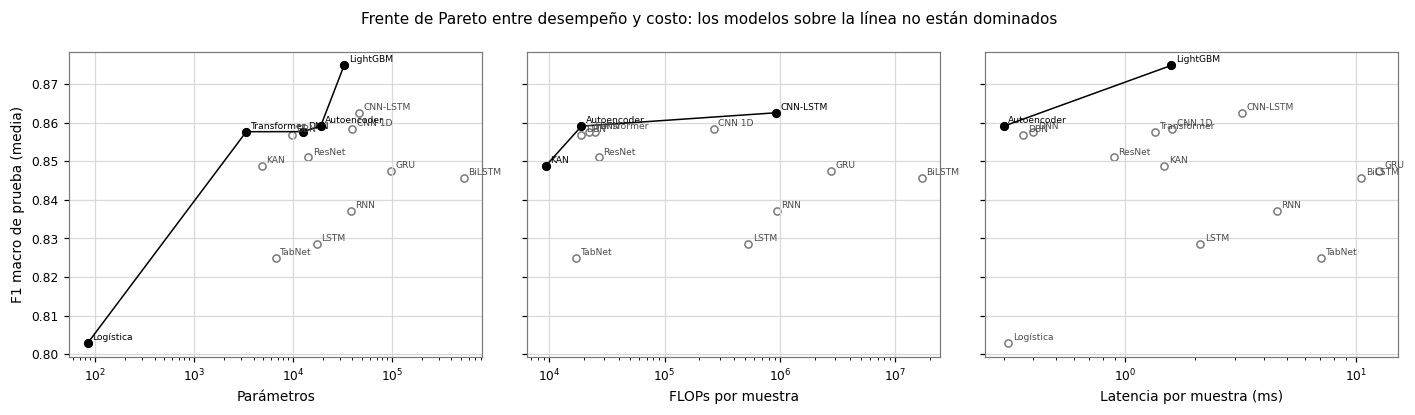

Modelo,Ganancia de F1 frente a Logística,IC 95 % de la ganancia,Δ latencia (ms),η: F1 por ms adicional
DNN,"+0,0547","[0,0314; 0,0848]","+0,089","+0,6139"
CNN 1D,"+0,0554","[0,0334; 0,0855]","+1,283","+0,0432"
LSTM,"+0,0255","[-0,0027; 0,0565]","+1,804","+0,0141"
CNN-LSTM,"+0,0596","[0,0348; 0,0943]","+2,895","+0,0206"
Autoencoder,"+0,0561","[0,0352; 0,0853]","-0,013","-4,3122"
RNN,"+0,0341","[0,0084; 0,0622]","+4,221","+0,0081"
Transformer,"+0,0547","[0,0348; 0,0815]","+1,037","+0,0527"
BiLSTM,"+0,0427","[0,0195; 0,0714]","+10,228","+0,0042"
ResNet,"+0,0480","[0,0254; 0,0785]","+0,579","+0,0829"
GRU,"+0,0444","[0,0169; 0,0776]","+12,304","+0,0036"


**Interpretación.** En parámetros, la frontera de Pareto la forman Logística, Transformer, DNN, Autoencoder y LightGBM; en FLOPs, KAN, Autoencoder y CNN-LSTM, y en latencia, Autoencoder y LightGBM. Frente a Logística, el mejor baseline no profundo por validación, ganan F1 con un IC por bloques que excluye el cero DNN, CNN 1D, CNN-LSTM, Autoencoder, RNN, Transformer, BiLSTM, ResNet, GRU, KAN y DBN; LSTM y TabNet ganan en promedio, pero su IC incluye el cero. LightGBM y Logística no entran en el frente de FLOPs, porque esa medida no aplica a esos modelos.

Esto significa que la complejidad no compra desempeño de forma proporcional: entre los 13 modelos profundos, la correlación de Spearman entre parámetros y F1 macro es de 0,07 (p = 0,817), y el modelo con más parámetros, BiLSTM, no está en la frontera. Así mismo, 11 de los 13 modelos profundos ganan con claridad F1 frente a Logística, y η indica cuánto cuesta cada unidad de esa ganancia en latencia. Hay que tener en cuenta que Logística es el mejor baseline no profundo por validación, pero no en prueba, donde LightGBM lo supera; frente a LightGBM, la comparación es la de RQ2.

Por lo anterior, conviene preferir, entre modelos estadísticamente equivalentes, el que esté en la frontera de Pareto, que es la pregunta exploratoria RQ5 de la sección {ref}`6.3 <sec-6-3>`.

In [60]:
def no_dominados(score, costo_v):
    orden = np.argsort(costo_v)
    frente, mejor = [], -np.inf
    for i in orden:
        if score[i] > mejor:
            frente.append(i)
            mejor = score[i]
    return frente
modelos_p = [m for m in ORDEN if m != "Trivial"]
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
pareto = {}
for eje, (col, titulo) in zip(ejes, (("Parámetros", "Parámetros"), ("FLOPs", "FLOPs por muestra"), ("Latencia (ms)", "Latencia por muestra (ms)"))):
    con_medida = [m for m in modelos_p if np.isfinite(float(TABLA_A2.loc[m, col]))]
    x = TABLA_A2.loc[con_medida, col].astype(float).to_numpy()
    s = np.array([F1P[m].mean() for m in con_medida])
    frente = no_dominados(s, x)
    pareto[col] = [con_medida[i] for i in frente]
    eje.scatter(x, s, s=22, facecolors="white", edgecolors=GRIS_MEDIO)
    eje.plot(x[frente], s[frente], color=NEGRO, marker="o", ms=5, lw=1)
    for i, m in enumerate(con_medida):
        eje.annotate(m, (x[i], s[i]), fontsize=6, xytext=(3, 2), textcoords="offset points", color=NEGRO if i in frente else GRIS_OSCURO)
    eje.set_xscale("log")
    eje.set(xlabel=titulo)
ejes[0].set_ylabel("F1 macro de prueba (media)")
fig.suptitle("Frente de Pareto entre desempeño y costo: los modelos sobre la línea no están dominados", fontsize=10)
plt.tight_layout()
plt.show()
mejor_base = max(["LightGBM", "Logística"], key=lambda m: F1V[m].mean())
otro_base = "Logística" if mejor_base == "LightGBM" else "LightGBM"
eficiencia = []
for m in PROFUNDOS:
    ganancia = F1_BOOT[m] - F1_BOOT[mejor_base]
    d_lat = costo.loc[m, "ms_por_muestra"] - costo.loc[mejor_base, "ms_por_muestra"]
    eficiencia.append({"Modelo": m, "Ganancia de F1 frente a " + mejor_base: F1P[m].mean() - F1P[mejor_base].mean(), "IC 95 % de la ganancia": intervalo(E.ic_percentil(ganancia)),
                       "Δ latencia (ms)": d_lat, "η: F1 por ms adicional": (F1P[m].mean() - F1P[mejor_base].mean()) / d_lat if d_lat else np.nan})
tabla(pd.DataFrame(eficiencia), {"Ganancia de F1 frente a " + mejor_base: "{:+.4f}", "Δ latencia (ms)": "{:+.3f}", "η: F1 por ms adicional": "{:+.4f}"})
params_dl = np.array([costo.loc[m, "Parámetros"] for m in PROFUNDOS], float)
rho_p = stats.spearmanr(params_dl, [F1P[m].mean() for m in PROFUNDOS])
mas_grande = PROFUNDOS[int(np.argmax(params_dl))]
ganan_base = [m for m in PROFUNDOS if E.ic_percentil(F1_BOOT[m] - F1_BOOT[mejor_base])[0] > 0]
ganan_punto = [m for m in PROFUNDOS if F1P[m].mean() > F1P[mejor_base].mean() and m not in ganan_base]
sin_flops = [m for m in modelos_p if m not in pareto["FLOPs"] and not np.isfinite(float(TABLA_A2.loc[m, "FLOPs"]))]
interpretar(f'''**Interpretación.** En parámetros, la frontera de Pareto la forman {enumerar(pareto["Parámetros"])}; en FLOPs, {enumerar(pareto["FLOPs"])}, y en latencia, {enumerar(pareto["Latencia (ms)"])}. Frente a {mejor_base}, el mejor baseline no profundo por validación, {("gana F1 con un IC por bloques que excluye el cero " if len(ganan_base) == 1 else "ganan F1 con un IC por bloques que excluye el cero ") + enumerar(ganan_base) if ganan_base else "ningún modelo profundo gana F1 con un IC por bloques que excluya el cero"}{f"; {enumerar(ganan_punto)} {'gana' if len(ganan_punto) == 1 else 'ganan'} en promedio, pero su IC incluye el cero" if ganan_punto else ""}.{f" {enumerar(sin_flops)} no {'entra' if len(sin_flops) == 1 else 'entran'} en el frente de FLOPs, porque esa medida no aplica a {'un modelo de árboles' if sin_flops == ['LightGBM'] else 'esos modelos'}." if sin_flops else ""}

Esto significa que {"más parámetros se asocian con más desempeño" if rho_p.statistic > 0 and rho_p.pvalue < ALFA else "la complejidad no compra desempeño de forma proporcional"}: {f"entre los 13 modelos profundos, la correlación de Spearman entre parámetros y F1 macro es de {num(rho_p.statistic, 2)} ({valor_p(rho_p.pvalue)}), y " if np.isfinite(rho_p.statistic) else ""}el modelo con más parámetros, {mas_grande}, {"está" if mas_grande in pareto["Parámetros"] else "no está"} en la frontera. Así mismo, {f"{len(PROFUNDOS) - len(ganan_base)} de los 13 modelos profundos quedan por debajo de {mejor_base} en F1, de modo que en ellos el costo adicional no compra desempeño" if len(ganan_base) + len(ganan_punto) < len(PROFUNDOS) else f"{'todos los modelos profundos ganan' if not ganan_punto else f'{len(ganan_base)} de los 13 modelos profundos ganan con claridad'} F1 frente a {mejor_base}, y η indica cuánto cuesta cada unidad de esa ganancia en latencia"}.{f" Hay que tener en cuenta que {mejor_base} es el mejor baseline no profundo por validación, pero no en prueba, donde {otro_base} lo supera; frente a {otro_base}, la comparación es la de RQ2." if F1P[otro_base].mean() > F1P[mejor_base].mean() else ""}

Por lo anterior, conviene preferir, entre modelos estadísticamente equivalentes, el que esté en la frontera de Pareto, que es la pregunta exploratoria RQ5 de la sección 6.3.''')

(sec-6-3)=
## 6.3 Análisis estadístico y pruebas de hipótesis

**Verificación de supuestos.** Antes de elegir la prueba se verifican la normalidad de las diferencias pareadas con Shapiro-Wilk (Shapiro y Wilk, 1965), la homogeneidad de varianzas entre modelos con Brown-Forsythe (Brown y Forsythe, 1974) y la esfericidad con Mauchly (1940). La independencia se cumple a nivel de semilla, la unidad de las pruebas pareadas: cada semilla es una corrida independiente sobre la misma partición. Las R corridas comparten el conjunto de prueba, de modo que las inferencias valen para esta prueba y no para otra muestra de series; la variabilidad por partición se mide aparte, en el contraste de RQ2, con la validación cruzada 5 × 2.

In [61]:
M_ALL = F1P[ORDEN].to_numpy()
levene = stats.levene(*[F1P[m].to_numpy() for m in ORDEN if m != "Trivial"], center="median")
mauchly = E.mauchly(F1P[[m for m in ORDEN if m != "Trivial"]].to_numpy())
base = CONFIG["modelos"]["baseline_e1"]
shapiro_pares = {m: stats.shapiro(F1P[m] - F1P[base]).pvalue for m in CONFIG["modelos"]["top10"]}
tabla(pd.DataFrame({"Supuesto": ["Normalidad de las diferencias frente a CNN 1D (Shapiro-Wilk)", "Homogeneidad de varianzas (Brown-Forsythe)", "Esfericidad (Mauchly)"],
                    "Resultado": [f"{sum(p >= ALFA for p in shapiro_pares.values())} de 10 contrastes no rechazan; p de {num(min(shapiro_pares.values()), 3)} a {num(max(shapiro_pares.values()), 3)}",
                                  f"W = {num(levene.statistic, 3)}, {valor_p(levene.pvalue)}",
                                  f"W = {num(mauchly['W'], 4)}, {valor_p(mauchly['p'])}" if np.isfinite(mauchly["p"]) else f"No calculable: {R} semillas frente a {len(ORDEN) - 2} contrastes entre modelos"],
                    "Consecuencia": ["Prueba (i): t pareada donde no se rechaza; bootstrap pareado donde sí",
                                     "Las pruebas pareadas no suponen varianzas iguales entre modelos" if levene.pvalue < ALFA else "No se rechaza la homogeneidad; las pruebas pareadas no la requieren",
                                     "Se rechaza la esfericidad; la ANOVA de medidas repetidas se corrige con Greenhouse-Geisser" if np.isfinite(mauchly["p"]) and mauchly["p"] < ALFA else "La ANOVA de medidas repetidas se reporta con la corrección de Greenhouse-Geisser, por prudencia"]}))

Supuesto,Resultado,Consecuencia
Normalidad de las diferencias frente a CNN 1D (Shapiro-Wilk),"8 de 10 contrastes no rechazan; p de 0,011 a 0,939",Prueba (i): t pareada donde no se rechaza; bootstrap pareado donde sí
Homogeneidad de varianzas (Brown-Forsythe),"W = 7,811, p < 0,001",Las pruebas pareadas no suponen varianzas iguales entre modelos
Esfericidad (Mauchly),"W = 0,0000, p < 0,001",Se rechaza la esfericidad; la ANOVA de medidas repetidas se corrige con Greenhouse-Geisser


**RQ1: el Top 10 frente al baseline del Entregable 1.** Cada modelo del Top 10 se compara con CNN 1D, reentrenada en este entregable con el mismo protocolo, con las tres pruebas preregistradas (la *t* pareada o el *bootstrap* pareado, Efron y Tibshirani, 1993; Wilcoxon, 1945, y Friedman con *post hoc*) y la corrección de Holm (1979) dentro de la familia de 10 contrastes. Se agregan la *d* de Cohen (1988), TOST (Schuirmann, 1987) y la prueba bayesiana de rangos con signo con ROPE de ±δ (Benavoli et al., 2017). La tabla sigue la plantilla A.3 del enunciado.

In [62]:
def contrastes(pares, familia):
    filas_c = []
    for a, b in pares:
        r_c = E.comparar_par(F1P[a].to_numpy(), F1P[b].to_numpy())
        boot = F1_BOOT[a] - F1_BOOT[b]
        filas_c.append({"Contraste": f"{a} − {b}", "a": a, "b": b, **r_c, "IC 95 % por bloques": E.ic_percentil(boot)})
    t = pd.DataFrame(filas_c)
    t["p (i)"] = np.where(t["Shapiro-Wilk p"] >= ALFA, t["p t pareada"], t["p bootstrap"])
    t["Prueba (i)"] = np.where(t["Shapiro-Wilk p"] >= ALFA, "t pareada", "bootstrap pareado")
    t["p (i) Holm"] = E.holm(t["p (i)"])
    t["p Wilcoxon Holm"] = E.holm(t["p Wilcoxon"])
    t["Decisión"] = [E.decision(fila, fila["p (i) Holm"], fila["p Wilcoxon Holm"]) for _, fila in t.iterrows()]
    t["Familia"] = familia
    return t
RQ1 = contrastes([(m, base) for m in CONFIG["modelos"]["top10"]], "F1")
def presentar(t):
    return pd.DataFrame({"Contraste": t["Contraste"], "Prueba (i)": t["Prueba (i)"], "Diferencia": t["Diferencia media"],
                         "IC 95 % (semillas)": [intervalo(f["IC 95 % t"] if f["Shapiro-Wilk p"] >= ALFA else f["IC 95 % bootstrap"]) for _, f in t.iterrows()],
                         "IC 95 % (bloques)": [intervalo(x) for x in t["IC 95 % por bloques"]], "d de Cohen": t["d de Cohen pareada"], "δ de Cliff": t["δ de Cliff"],
                         "p (i)": t["p (i)"].map(p_exacto), "p (i) Holm": t["p (i) Holm"].map(p_exacto), "p Wilcoxon": t["p Wilcoxon"].map(p_exacto), "p Wilcoxon Holm": t["p Wilcoxon Holm"].map(p_exacto),
                         "p TOST": t["p TOST"].map(p_exacto), "P(ROPE) bayesiana": t["P(ROPE)"], "Potencia para δ": t["Potencia para δ"], "Decisión frente a δ": t["Decisión"]})
tabla(presentar(RQ1), {"Diferencia": "{:+.4f}", "d de Cohen": "{:.2f}", "δ de Cliff": "{:.2f}", "P(ROPE) bayesiana": "{:.3f}", "Potencia para δ": "{:.3f}"})
RQ1.to_csv(RESULTADOS / "contrastes_rq1.csv", index=False)
dec = RQ1["Decisión"].value_counts()
DECISION_TXT = {"No concluyente": ("no concluyente", "no concluyentes"), "Equivalente": ("equivalente", "equivalentes"),
                "Significativa y relevante": ("significativo y relevante", "significativos y relevantes"), "Significativa sin relevancia": ("significativo sin relevancia", "significativos sin relevancia")}
def lectura_rq1():
    sig = RQ1["Decisión"].str.startswith("Significativa")
    rel_pos = RQ1.loc[RQ1["Decisión"].eq("Significativa y relevante") & (RQ1["Diferencia media"] > 0), "a"].tolist()
    sin_rel = RQ1.loc[RQ1["Decisión"].eq("Significativa sin relevancia") & (RQ1["Diferencia media"] > 0), "a"].tolist()
    neg = RQ1.loc[RQ1["Decisión"].eq("Significativa y relevante") & (RQ1["Diferencia media"] < 0), "a"].tolist()
    neg_sin = RQ1.loc[RQ1["Decisión"].eq("Significativa sin relevancia") & (RQ1["Diferencia media"] < 0), "a"].tolist()
    nc = RQ1.loc[RQ1["Decisión"].eq("No concluyente"), "a"].tolist()
    equiv = RQ1.loc[RQ1["Decisión"].eq("Equivalente"), "a"].tolist()
    n_nc = int(RQ1["Decisión"].eq("No concluyente").sum())
    partes = ["Esto quiere decir que " + (f"{enumerar(rel_pos)} {'supera' if len(rel_pos) == 1 else 'superan'} al baseline del Entregable 1 de forma significativa y relevante, de modo que H0 se rechaza a su favor"
                                          if rel_pos else "ningún modelo del Top 10 supera al baseline del Entregable 1 en una magnitud mayor que δ con evidencia estadística, de modo que H0 no se rechaza a favor del Top 10 en ningún contraste") + "."]
    if sin_rel:
        partes.append(f"{enumerar(sin_rel)} {'lo supera' if len(sin_rel) == 1 else 'lo superan'} de forma significativa, pero por menos de δ, de modo que la mejora no es relevante.")
    if neg or neg_sin:
        partes.append("En cambio, " + (f"{enumerar(neg)} {'queda' if len(neg) == 1 else 'quedan'} por debajo del baseline en más de δ" if neg else "")
                      + (", y " if neg and neg_sin else "") + (f"{enumerar(neg_sin)} {'queda' if len(neg_sin) == 1 else 'quedan'} por debajo de forma significativa, pero por menos de δ" if neg_sin else "") + ".")
    if equiv:
        partes.append(f"{enumerar(equiv)} {'es equivalente' if len(equiv) == 1 else 'son equivalentes'} al baseline dentro de ±δ según TOST.")
    if n_nc:
        partes.append(f"{'El contraste no concluyente, el de ' + nc[0] + ', no permite' if n_nc == 1 else f'Los {n_nc} contrastes no concluyentes, los de {enumerar(nc)}, no permiten'} afirmar ni superioridad ni equivalencia, porque su intervalo no excluye el cero ni cabe dentro de ±δ.")
    partes.append("La prueba bayesiana, con su probabilidad de estar dentro del ROPE, complementa esa lectura sin control de error por familia.")
    return " ".join(partes)
interpretar(f'''**Interpretación.** De los 10 contrastes de RQ1, {enumerar([f"{v} {('es ' if v == 1 else 'son ') if i == 0 else ''}{DECISION_TXT.get(k, (k.lower(), k.lower()))[0 if v == 1 else 1]}" for i, (k, v) in enumerate(dec.items())])}. Las diferencias frente a CNN 1D van de {num(RQ1["Diferencia media"].min(), 4)} ({RQ1.loc[RQ1["Diferencia media"].idxmin(), "a"]}) a {num(RQ1["Diferencia media"].max(), 4)} ({RQ1.loc[RQ1["Diferencia media"].idxmax(), "a"]}), con una potencia para δ de {num(RQ1["Potencia para δ"].min(), 2)} a {num(RQ1["Potencia para δ"].max(), 2)}.

{lectura_rq1()}

Por tanto, corresponde responder RQ1 con la columna de decisión, que aplica la regla del preregistro, y no con el orden de la tabla 6.1.''')

Contraste,Prueba (i),Diferencia,IC 95 % (semillas),IC 95 % (bloques),d de Cohen,δ de Cliff,p (i),p (i) Holm,p Wilcoxon,p Wilcoxon Holm,p TOST,P(ROPE) bayesiana,Potencia para δ,Decisión frente a δ
CNN-LSTM − CNN 1D,bootstrap pareado,"+0,0041","[-0,0042; 0,0115]","[-0,0112; 0,0240]","0,22","0,42","0,3114","1,0000","0,1429","0,5716","0,0866","0,704","0,627",No concluyente
Autoencoder − CNN 1D,t pareada,"+0,0007","[-0,0043; 0,0056]","[-0,0085; 0,0136]","0,06","0,01","0,7829","1,0000","0,9273","1,0000","0,0004","1,000","0,981",Equivalente
RNN − CNN 1D,bootstrap pareado,"-0,0213","[-0,0296; -0,0123]","[-0,0345; -0,0083]","-1,05","-0,66","1,00e-04","0,0009","0,0003","0,0029","0,9892","0,006","0,555",Significativa y relevante
Transformer − CNN 1D,t pareada,"-0,0008","[-0,0069; 0,0053]","[-0,0118; 0,0124]","-0,06","0,12","0,7902","1,0000","0,9273","1,0000","0,0026","0,998","0,901",Equivalente
BiLSTM − CNN 1D,t pareada,"-0,0127","[-0,0244; -0,0011]","[-0,0262; -0,0005]","-0,51","-0,33","0,0334","0,1934","0,0362","0,2174","0,6858","0,451","0,401",No concluyente
ResNet − CNN 1D,t pareada,"-0,0075","[-0,0142; -0,0007]","[-0,0193; 0,0074]","-0,52","-0,33","0,0322","0,1934","0,0400","0,2174","0,2215","0,821","0,835",No concluyente
GRU − CNN 1D,t pareada,"-0,0110","[-0,0168; -0,0053]","[-0,0224; 0,0011]","-0,90","-0,59","0,0007","0,0058","0,0010","0,0081","0,6431","0,506","0,933",Significativa y relevante
KAN − CNN 1D,t pareada,"-0,0096","[-0,0159; -0,0033]","[-0,0209; 0,0033]","-0,71","-0,51","0,0050","0,0351","0,0049","0,0340","0,4473","0,636","0,880",Significativa sin relevancia
TabNet − CNN 1D,t pareada,"-0,0335","[-0,0432; -0,0238]","[-0,0499; -0,0202]","-1,62","-0,87","7,39e-07","7,39e-06","5,72e-06","5,72e-05","1,0000","0,000","0,535",Significativa y relevante
DBN − CNN 1D,t pareada,"-0,0016","[-0,0058; 0,0027]","[-0,0123; 0,0071]","-0,17","-0,11","0,4579","1,0000","0,6742","1,0000","0,0003","1,000","0,996",Equivalente


**Interpretación.** De los 10 contrastes de RQ1, 3 son no concluyentes, 3 equivalentes, 3 significativos y relevantes y 1 significativo sin relevancia. Las diferencias frente a CNN 1D van de -0,0335 (TabNet) a 0,0041 (CNN-LSTM), con una potencia para δ de 0,40 a 1,00.

Esto quiere decir que ningún modelo del Top 10 supera al baseline del Entregable 1 en una magnitud mayor que δ con evidencia estadística, de modo que H0 no se rechaza a favor del Top 10 en ningún contraste. En cambio, RNN, GRU y TabNet quedan por debajo del baseline en más de δ, y KAN queda por debajo de forma significativa, pero por menos de δ. Autoencoder, Transformer y DBN son equivalentes al baseline dentro de ±δ según TOST. Los 3 contrastes no concluyentes, los de CNN-LSTM, BiLSTM y ResNet, no permiten afirmar ni superioridad ni equivalencia, porque su intervalo no excluye el cero ni cabe dentro de ±δ. La prueba bayesiana, con su probabilidad de estar dentro del ROPE, complementa esa lectura sin control de error por familia.

Por tanto, corresponde responder RQ1 con la columna de decisión, que aplica la regla del preregistro, y no con el orden de la tabla 6.1.

**Procedimiento global.** Friedman (1937), con la corrección de Iman y Davenport (1980), compara los 16 modelos con las semillas como bloques; el *post hoc* de Nemenyi da la distancia crítica del diagrama (Demšar, 2006), y el de Wilcoxon con Holm, las comparaciones por pares. Se complementa con la ANOVA de medidas repetidas con la corrección de Greenhouse y Geisser (1959) y con el *Model Confidence Set* de Hansen et al. (2011) al 90 %, sobre la pérdida 1 − F1 macro por bloque de prueba.

Prueba,Estadístico,p,Tamaño de efecto
Friedman,"184,80","2,55e-31","W de Kendall = 0,616"
Iman-Davenport,"30,48","1,62e-50",
ANOVA de medidas repetidas (Greenhouse-Geisser),"3782,25","1,14e-121","η² parcial = 0,995; ε = 0,378"


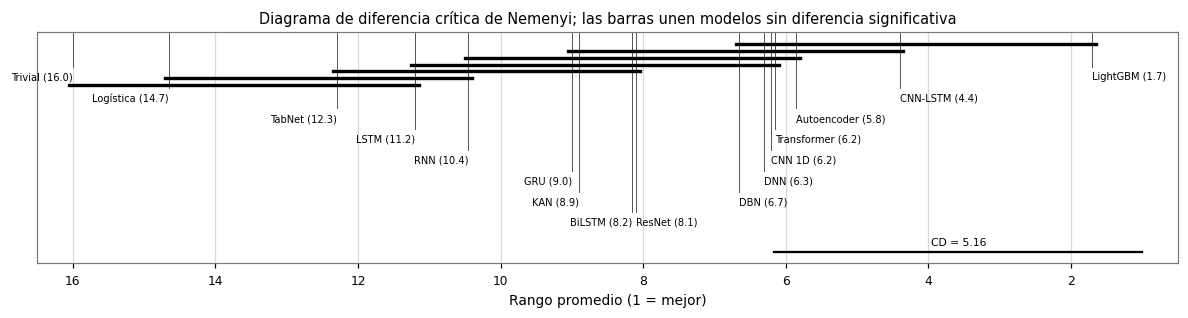

Pares significativos con Wilcoxon-Holm: 58 de 120


Model Confidence Set al 90 %: DNN, CNN 1D, CNN-LSTM, Autoencoder, Transformer, ResNet, GRU, KAN, DBN y LightGBM


**Interpretación.** Friedman rechaza la igualdad de rangos de los 16 modelos, con χ² = 184,8 (p < 0,001); la corrección de Iman y Davenport da p < 0,001, con una W de Kendall de 0,616, y la ANOVA de medidas repetidas coincide (p < 0,001, ε de Greenhouse-Geisser = 0,378). La distancia crítica de Nemenyi es de 5,16 rangos, y el *Model Confidence Set* al 90 % conserva 10 modelos: DNN, CNN 1D, CNN-LSTM, Autoencoder, Transformer, ResNet, GRU, KAN, DBN y LightGBM.

Es decir, hay diferencias entre los modelos: de los 120 pares, 58 son significativos con Wilcoxon-Holm, 15 de ellos frente al trivial. El MCS deja en la cima 10 modelos que estos datos no pueden separar. Hay que tener en cuenta que Nemenyi es conservador con 16 modelos y 20 semillas, y que el MCS opera sobre los 24 bloques de prueba, la unidad independiente, de modo que su conjunto es la lectura más honesta de qué modelos están en la cima.

Por ello, se recomienda presentar como ganadores al conjunto del MCS y no a un solo modelo.

In [63]:
fr = E.friedman(M_ALL)
anova_rm = E.anova_repetidas(M_ALL)
rangos_n, p_nem, cd = E.nemenyi(M_ALL)
tabla(pd.DataFrame({"Prueba": ["Friedman", "Iman-Davenport", "ANOVA de medidas repetidas (Greenhouse-Geisser)"], "Estadístico": [fr["chi2"], fr["F Iman-Davenport"], anova_rm["F"]],
                    "p": [p_exacto(fr["p"]), p_exacto(fr["p Iman-Davenport"]), p_exacto(anova_rm["p GG"])],
                    "Tamaño de efecto": [f"W de Kendall = {num(fr['W de Kendall'], 3)}", "", f"η² parcial = {num(anova_rm['η² parcial'], 3)}; ε = {num(anova_rm['épsilon GG'], 3)}"]}),
      {"Estadístico": "{:.2f}"})
orden_r = np.argsort(rangos_n)
fig, eje = plt.subplots(figsize=(11, 3.0))
eje.set(xlim=(len(ORDEN) + 0.5, 0.5), ylim=(0, 1))
eje.yaxis.set_visible(False)
for i, j in enumerate(orden_r):
    lado = i < len(ORDEN) / 2
    yy = 0.85 - 0.09 * (i if lado else len(ORDEN) - 1 - i)
    eje.plot([rangos_n[j]] * 2, [1, yy], color=GRIS_OSCURO, lw=0.6)
    eje.text(rangos_n[j], yy - 0.02, f"{ORDEN[j]} ({rangos_n[j]:.1f})", ha="left" if lado else "right", va="top", fontsize=6.5)
grupos_cd = []
for i in range(len(orden_r)):
    fin = max([k for k in range(i, len(orden_r)) if rangos_n[orden_r[k]] - rangos_n[orden_r[i]] <= cd], default=i)
    if fin > i and not any(g[0] <= i and fin <= g[1] for g in grupos_cd):
        grupos_cd.append((i, fin))
for n_g, (i, fin) in enumerate(grupos_cd):
    eje.plot([rangos_n[orden_r[i]] - 0.05, rangos_n[orden_r[fin]] + 0.05], [0.95 - 0.03 * n_g] * 2, color=NEGRO, lw=2.2)
eje.plot([1, 1 + cd], [0.05] * 2, color=NEGRO, lw=1.5)
eje.text(1 + cd / 2, 0.08, f"CD = {cd:.2f}", ha="center", fontsize=7)
eje.set_xlabel("Rango promedio (1 = mejor)")
eje.set_title("Diagrama de diferencia crítica de Nemenyi; las barras unen modelos sin diferencia significativa", fontsize=9.5)
plt.tight_layout()
plt.show()
p_wh = np.ones((len(ORDEN), len(ORDEN)))
pares_todos = [(i, j) for i in range(len(ORDEN)) for j in range(i + 1, len(ORDEN))]
p_crudos = [stats.wilcoxon(M_ALL[:, i] - M_ALL[:, j]).pvalue if np.any(M_ALL[:, i] != M_ALL[:, j]) else 1.0 for i, j in pares_todos]
for (i, j), ph in zip(pares_todos, E.holm(p_crudos)):
    p_wh[i, j] = p_wh[j, i] = ph
WILCOXON_HOLM = pd.DataFrame(p_wh, index=ORDEN, columns=ORDEN)
print(f"Pares significativos con Wilcoxon-Holm: {int((np.triu(p_wh, 1)[np.triu_indices(len(ORDEN), 1)] < ALFA).sum())} de {len(pares_todos)}")
perdida_bloque = np.column_stack([1 - np.mean([[AN.f1_desde_conteos(CONF_BLOQUES[f"{i}|eva"][b]) for b in range(NB_PRU)] for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]], 0)
                                  for m in modelos_p])
mcs = E.model_confidence_set(perdida_bloque, nivel=0.10)
MCS = [modelos_p[i] for i in mcs["conjunto"]]
print(f"Model Confidence Set al 90 %: {enumerar(MCS)}")
sig_pares = [(ORDEN[i], ORDEN[j]) for i, j in pares_todos if p_wh[i, j] < ALFA]
n_sig_trivial = sum("Trivial" in par for par in sig_pares)
global_rechaza = fr["p Iman-Davenport"] < ALFA
interpretar(f'''**Interpretación.** Friedman {"rechaza" if fr["p"] < ALFA else "no rechaza"} la igualdad de rangos de los {len(ORDEN)} modelos, con χ² = {num(fr["chi2"], 1)} ({valor_p(fr["p"])}); la corrección de Iman y Davenport da {valor_p(fr["p Iman-Davenport"])}, con una W de Kendall de {num(fr["W de Kendall"], 3)}, y la ANOVA de medidas repetidas {"coincide" if (anova_rm["p GG"] < ALFA) == global_rechaza else "no coincide"} ({valor_p(anova_rm["p GG"])}, ε de Greenhouse-Geisser = {num(anova_rm["épsilon GG"], 3)}). La distancia crítica de Nemenyi es de {num(cd, 2)} rangos, y el *Model Confidence Set* al 90 % {"conserva un solo modelo, " + MCS[0] if len(MCS) == 1 else f"conserva {len(MCS)} modelos: " + enumerar(MCS)}.

Es decir, {"hay diferencias entre los modelos" if global_rechaza else "no hay evidencia de diferencias globales entre los modelos"}{f": de los {len(pares_todos)} pares, {len(sig_pares)} son significativos con Wilcoxon-Holm, {n_sig_trivial} de ellos frente al trivial" if sig_pares else (f", aunque ningún par es significativo con Wilcoxon-Holm: con {R} semillas, el p exacto mínimo de Wilcoxon es {p_exacto(2 / 2 ** R)}, y la corrección de Holm sobre {len(pares_todos)} pares lo lleva por encima de α" if 2 / 2 ** R * len(pares_todos) >= ALFA else f", aunque ningún par de los {len(pares_todos)} es significativo con Wilcoxon-Holm")}. {f"El MCS deja en la cima a un solo modelo, {MCS[0]}: con un nivel de 0,10, ningún otro iguala su pérdida por bloque." if len(MCS) == 1 else f"El MCS deja en la cima {len(MCS)} modelos que estos datos no pueden separar."} Hay que tener en cuenta que Nemenyi es conservador con {len(ORDEN)} modelos y {R} semillas, y que el MCS opera sobre los {NB_PRU} bloques de prueba, la unidad independiente, de modo que su conjunto es la lectura más honesta de qué modelos están en la cima.

{"Por ello, se recomienda presentar como ganadores al conjunto del MCS y no a un solo modelo." if len(MCS) > 1 else f"Por ello, se presenta a {MCS[0]} como el mejor modelo del benchmark, con la salvedad de que la conclusión vale para estas series de prueba."}''')

**RQ2: el mejor modelo profundo frente a LightGBM.** El mejor modelo profundo se elige por su F1 macro medio de validación, para no sesgar el contraste con la propia prueba. Además de las tres pruebas preregistradas y TOST, se reportan McNemar (1947) y DeLong et al. (1988) sobre el promedio de probabilidades de las R semillas, que suponen filas independientes, y la *F* de 5 × 2 cv de Alpaydin (1999) y la *t* con la corrección de Nadeau y Bengio (2003) sobre la validación cruzada 5 × 2 agrupada, que miden también la variabilidad por partición.

In [64]:
RQ2 = contrastes([(MEJOR_DL, "LightGBM")], "F2")
RQ2.to_csv(RESULTADOS / "contrastes_rq2.csv", index=False)
tabla(presentar(RQ2), {"Diferencia": "{:+.4f}", "d de Cohen": "{:.2f}", "δ de Cliff": "{:.2f}", "P(ROPE) bayesiana": "{:.3f}", "Potencia para δ": "{:.3f}"})
ens = {m: np.mean([AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "eva") for s in SEMILLAS], 0) for m in (MEJOR_DL, "LightGBM")}
mc = E.mcnemar_exacta(ens[MEJOR_DL].argmax(1) == y_pru, ens["LightGBM"].argmax(1) == y_pru)
dl_clases = [E.delong(y_pru == c, ens[MEJOR_DL][:, c], ens["LightGBM"][:, c]) for c in range(K)]
cv = RES.tabla_fase("cv5x2")
def diferencias_cv(a, b):
    pa = cv[cv["modelo"] == a].set_index("particion")["f1_eva"]
    pb = cv[cv["modelo"] == b].set_index("particion")["f1_eva"]
    nombres_cv = sorted(pa.index)
    return (pa[nombres_cv] - pb[nombres_cv]).to_numpy()
d_cv = diferencias_cv(MEJOR_DL, "LightGBM")
nb = E.nadeau_bengio(d_cv, 1, 1)
f52 = E.f_5x2cv(d_cv)
tabla(pd.DataFrame({"Prueba complementaria": ["McNemar (promedio de semillas)", *[f"DeLong, AUC de {CLASES[c]} uno contra todos" for c in range(K)], "t de Nadeau-Bengio (5 × 2 cv)", "F de 5 × 2 cv (Alpaydin)"],
                    "Diferencia o estadístico": [f"b = {mc['b']}, c = {mc['c']}", *[f"{num(d['diferencia'], 4)}" for d in dl_clases], f"diferencia media {num(d_cv.mean(), 4)}, t = {num(nb['t'], 2)}", f"F = {num(f52['F'], 2)}"],
                    "p": [p_exacto(mc["p"]), *[p_exacto(ph) for ph in E.holm([d["p"] for d in dl_clases])], p_exacto(nb["p"]), p_exacto(f52["p"])],
                    "Nota": ["Supone filas independientes", *["p con Holm entre las 5 clases"] * K, "Corrige el solapamiento de entrenamiento", "Alternativa con pocas ejecuciones"]}))
r2 = RQ2.iloc[0]
p_delong = E.holm([d["p"] for d in dl_clases])
filas_sig = mc["p"] < ALFA or min(p_delong) < ALFA
semillas_sig = r2["Decisión"].startswith("Significativa")
if r2["Decisión"] == "Significativa y relevante" and r2["Diferencia media"] > 0:
    lectura_rq2 = "el mejor modelo profundo supera al árbol potenciado de forma significativa y relevante, a pesar de que en datos tabulares los árboles potenciados suelen ser la referencia más difícil de batir"
elif semillas_sig and r2["Diferencia media"] < 0:
    lectura_rq2 = "el árbol potenciado supera al mejor modelo profundo de forma significativa, lo que es coherente con la advertencia del enunciado: en tablas de pocos atributos, los árboles potenciados son una referencia muy difícil de batir"
elif semillas_sig:
    lectura_rq2 = "el mejor modelo profundo supera al árbol potenciado de forma significativa, pero por menos de δ, de modo que la ventaja no es relevante en la práctica"
elif r2["Decisión"] == "Equivalente":
    lectura_rq2 = "el mejor modelo profundo y el árbol potenciado son equivalentes dentro de ±δ, de modo que la arquitectura profunda no aporta F1 frente a un modelo más barato"
else:
    lectura_rq2 = "el mejor modelo profundo no supera al árbol potenciado ajustado con el mismo presupuesto, aunque estos datos tampoco permiten declararlos equivalentes"
cv_sig = nb["p"] < ALFA
ic_b2 = r2["IC 95 % por bloques"]
if semillas_sig and not cv_sig:
    lectura_cv = (f" Sin embargo, la ventaja depende de las series de la prueba: en la validación cruzada 5 × 2, que reparte entre ajuste y evaluación los {NB_ENT + NB_VAL} bloques de entrenamiento y validación sin tocar la prueba, "
                  f"la diferencia media es de {num(d_cv.mean(), 4)} ({valor_p(nb['p'])}), y el IC por bloques de la prueba {'contiene al cero' if ic_b2[0] <= 0 <= ic_b2[1] else 'excluye el cero'}. "
                  f"Es decir, la regla preregistrada compara {R} semillas sobre las mismas {NB_PRU} series de prueba, de modo que detecta una diferencia real en esas series, pero no garantiza que se repita en series nuevas; "
                  "en otras particiones del mismo archivo, los dos modelos empatan")
elif cv_sig and np.sign(d_cv.mean()) == np.sign(r2["Diferencia media"]):
    lectura_cv = f" La validación cruzada 5 × 2, que cambia los datos de ajuste, confirma el signo de la diferencia ({num(d_cv.mean(), 4)}; {valor_p(nb['p'])}), de modo que la conclusión no depende solo de las series de la prueba"
else:
    lectura_cv = ""
if filas_sig and not semillas_sig:
    lectura_filas = "La discrepancia entre las pruebas por semillas y las pruebas por filas ilustra por qué estas últimas no sustentan conclusiones: con 22 883 flujos tratados como independientes, McNemar y DeLong detectan diferencias minúsculas, cuando la unidad independiente es la serie."
elif not filas_sig:
    lectura_filas = "Las pruebas por filas tampoco detectan diferencias, lo que refuerza esa lectura."
else:
    lectura_filas = "Las pruebas por filas coinciden, aunque su valor p es optimista porque tratan los flujos como independientes."
interpretar(f'''**Interpretación.** El mejor modelo profundo por validación es {MEJOR_DL}. Frente a LightGBM, su diferencia media en F1 macro de prueba es de {num(r2["Diferencia media"], 4)}, con IC 95 % por bloques de {intervalo(r2["IC 95 % por bloques"])}, y la decisión de la regla preregistrada es «{r2["Decisión"].lower()}» ({r2["Prueba (i)"]}: {valor_p(r2["p (i)"])}; Wilcoxon: {valor_p(r2["p Wilcoxon"])}; TOST: {valor_p(r2["p TOST"])}). En la validación cruzada 5 × 2, que cambia los datos de entrenamiento, la diferencia media es de {num(d_cv.mean(), 4)}, con {valor_p(nb["p"])} en la *t* de Nadeau y Bengio y {valor_p(f52["p"])} en la *F* de Alpaydin. McNemar da {valor_p(mc["p"])}, y DeLong, valores p con Holm entre {p_exacto(min(p_delong))} y {p_exacto(max(p_delong))} según la clase; ambas suponen filas independientes.

Esto significa que {lectura_rq2}.{lectura_cv}. {lectura_filas}

Por tal motivo, la respuesta a RQ2 es la decisión de la regla preregistrada{", acotada a las series de esta prueba" if lectura_cv.startswith(" Sin embargo") else ""}, y la justificación para usar un modelo profundo en lugar de LightGBM, si la hay, tiene que venir de otro eje: robustez, calibración o costo.''')

Contraste,Prueba (i),Diferencia,IC 95 % (semillas),IC 95 % (bloques),d de Cohen,δ de Cliff,p (i),p (i) Holm,p Wilcoxon,p Wilcoxon Holm,p TOST,P(ROPE) bayesiana,Potencia para δ,Decisión frente a δ
CNN 1D − LightGBM,t pareada,"-0,0164","[-0,0188; -0,0139]","[-0,0553; 0,0257]","-3,13","-1,00","1,83e-11","1,83e-11","1,91e-06","1,91e-06","1,0000","0,000","1,000",Significativa y relevante


Prueba complementaria,Diferencia o estadístico,p,Nota
McNemar (promedio de semillas),"b = 555, c = 978","4,37e-27",Supone filas independientes
"DeLong, AUC de Blackhole uno contra todos","-0,0119","1,40e-111",p con Holm entre las 5 clases
"DeLong, AUC de Flooding uno contra todos","-0,0092","3,08e-46",p con Holm entre las 5 clases
"DeLong, AUC de Normal uno contra todos","-0,0004","4,34e-12",p con Holm entre las 5 clases
"DeLong, AUC de Sybil uno contra todos","0,0064","0,0063",p con Holm entre las 5 clases
"DeLong, AUC de Wormhole uno contra todos","-0,0182","2,11e-148",p con Holm entre las 5 clases
t de Nadeau-Bengio (5 × 2 cv),"diferencia media -0,0003, t = -0,01","0,9902",Corrige el solapamiento de entrenamiento
F de 5 × 2 cv (Alpaydin),"F = 0,61","0,7645",Alternativa con pocas ejecuciones


**Interpretación.** El mejor modelo profundo por validación es CNN 1D. Frente a LightGBM, su diferencia media en F1 macro de prueba es de -0,0164, con IC 95 % por bloques de [-0,0553; 0,0257], y la decisión de la regla preregistrada es «significativa y relevante» (t pareada: p < 0,001; Wilcoxon: p < 0,001; TOST: p = 1,000). En la validación cruzada 5 × 2, que cambia los datos de entrenamiento, la diferencia media es de -0,0003, con p = 0,990 en la *t* de Nadeau y Bengio y p = 0,764 en la *F* de Alpaydin. McNemar da p < 0,001, y DeLong, valores p con Holm entre 2,11e-148 y 0,0063 según la clase; ambas suponen filas independientes.

Esto significa que el árbol potenciado supera al mejor modelo profundo de forma significativa, lo que es coherente con la advertencia del enunciado: en tablas de pocos atributos, los árboles potenciados son una referencia muy difícil de batir. Sin embargo, la ventaja depende de las series de la prueba: en la validación cruzada 5 × 2, que reparte entre ajuste y evaluación los 97 bloques de entrenamiento y validación sin tocar la prueba, la diferencia media es de -0,0003 (p = 0,990), y el IC por bloques de la prueba contiene al cero. Es decir, la regla preregistrada compara 20 semillas sobre las mismas 24 series de prueba, de modo que detecta una diferencia real en esas series, pero no garantiza que se repita en series nuevas; en otras particiones del mismo archivo, los dos modelos empatan. Las pruebas por filas coinciden, aunque su valor p es optimista porque tratan los flujos como independientes.

Por tal motivo, la respuesta a RQ2 es la decisión de la regla preregistrada, acotada a las series de esta prueba, y la justificación para usar un modelo profundo en lugar de LightGBM, si la hay, tiene que venir de otro eje: robustez, calibración o costo.

**RQ3: modelos que leen los atributos como secuencia frente a los que no suponen orden.** Para cada semilla se promedia el F1 macro de los seis modelos secuenciales (CNN 1D, LSTM, RNN, GRU, BiLSTM y CNN-LSTM) y el de los siete que no suponen orden (DNN, ResNet, Autoencoder, DBN, KAN, TabNet y Transformer), y se comparan los promedios con la *t* pareada y Wilcoxon. Como procedimiento global, un modelo lineal de efectos mixtos sobre el F1 macro por bloque de prueba, $y_{ijr} = \mu + \alpha_{g(j)} + u_i + v_r + \varepsilon_{ijr}$, estima el efecto del grupo con efectos aleatorios cruzados de bloque $u_i$ y de semilla $v_r$.

In [65]:
import statsmodels.formula.api as smf

SECUENCIA = ["CNN 1D", "LSTM", "RNN", "GRU", "BiLSTM", "CNN-LSTM"]
SIN_ORDEN = ["DNN", "ResNet", "Autoencoder", "DBN", "KAN", "TabNet", "Transformer"]
r3 = E.comparar_par(F1P[SECUENCIA].mean(1).to_numpy(), F1P[SIN_ORDEN].mean(1).to_numpy())
filas_mm = []
for m in PROFUNDOS:
    for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]:
        s_ = int(METRICAS.loc[METRICAS["id"] == i, "semilla"].iloc[0])
        for b in range(NB_PRU):
            filas_mm.append({"f1": AN.f1_desde_conteos(CONF_BLOQUES[f"{i}|eva"][b]), "modelo": m, "grupo": "secuencia" if m in SECUENCIA else "sin orden", "bloque": b, "semilla": s_})
MM = pd.DataFrame(filas_mm)
# Efectos aleatorios cruzados de bloque y de semilla: un solo grupo con dos componentes de varianza
CRUZADOS = {"bloque": "0 + C(bloque)", "semilla": "0 + C(semilla)"}
mixto = smf.mixedlm("f1 ~ C(grupo, Treatment('sin orden'))", MM, groups=np.ones(len(MM)), re_formula="0", vc_formula=CRUZADOS).fit(reml=True)
coef = mixto.params.iloc[1]
ic_mm = mixto.conf_int().iloc[1].to_numpy()
tabla(pd.DataFrame({"Prueba": ["t pareada sobre semillas", "Wilcoxon sobre semillas", "Modelo mixto (bloque y semilla aleatorios)"],
                    "Diferencia secuencia − sin orden": [r3["Diferencia media"], r3["Diferencia media"], coef],
                    "IC 95 %": [intervalo(r3["IC 95 % t"]), intervalo(r3["IC 95 % bootstrap"]), intervalo(ic_mm)],
                    "p": [p_exacto(r3["p t pareada"]), p_exacto(r3["p Wilcoxon"]), p_exacto(mixto.pvalues.iloc[1])]}), {"Diferencia secuencia − sin orden": "{:+.4f}"})
RQ3_DECISION = E.decision(r3, r3["p t pareada"] if r3["Shapiro-Wilk p"] >= ALFA else r3["p bootstrap"], r3["p Wilcoxon"])
mixto_var = smf.mixedlm("f1 ~ C(modelo)", MM, groups=np.ones(len(MM)), re_formula="0", vc_formula=CRUZADOS).fit(reml=True)
componentes = dict(zip(mixto_var.model.exog_vc.names, mixto_var.vcomp))
var_bloque, var_semilla, var_resid = float(componentes["bloque"]), float(componentes["semilla"]), float(mixto_var.scale)
efectos_fijos = mixto_var.fe_params.iloc[1:]
var_modelo = float(np.var(np.r_[0, efectos_fijos.to_numpy()]))
total_var = var_modelo + var_bloque + var_semilla + var_resid
DESCOMP = pd.DataFrame({"Componente": ["Modelo (efecto fijo)", "Bloque de prueba", "Semilla", "Residuo"], "Varianza": [var_modelo, var_bloque, var_semilla, var_resid]})
DESCOMP["% del total"] = 100 * DESCOMP["Varianza"] / total_var
razon_bm = var_bloque / var_modelo if var_modelo > 0 else np.inf
lectura_rq3 = {("Significativa y relevante", True): "imponer un orden a las columnas perjudica en una magnitud mayor que δ",
               ("Significativa y relevante", False): "leer los atributos como secuencia mejora el desempeño en una magnitud mayor que δ, aunque el orden de las columnas es arbitrario, de modo que el beneficio vendría de los pesos compartidos y de la recurrencia más que de un orden real",
               ("Significativa sin relevancia", True): "la diferencia en contra de los modelos secuenciales es real, pero menor que δ",
               ("Significativa sin relevancia", False): "la diferencia a favor de los modelos secuenciales es real, pero menor que δ",
               ("Equivalente", True): "los dos grupos son equivalentes dentro de ±δ: el supuesto de orden no cambia el desempeño",
               ("Equivalente", False): "los dos grupos son equivalentes dentro de ±δ: el supuesto de orden no cambia el desempeño",
               ("No concluyente", True): "estos datos no permiten afirmar que el supuesto de orden cambie el desempeño, ni que sea irrelevante",
               ("No concluyente", False): "estos datos no permiten afirmar que el supuesto de orden cambie el desempeño, ni que sea irrelevante"}[(RQ3_DECISION, bool(r3["Diferencia media"] < 0))]
tabla(DESCOMP, {"Varianza": "{:.6f}", "% del total": "{:.1f}"})
interpretar(f'''**Interpretación.** En RQ3, los modelos que leen los atributos como secuencia obtienen, en promedio por semilla, una diferencia de {num(r3["Diferencia media"], 4)} en F1 macro frente a los que no suponen orden, con IC 95 % de {intervalo(r3["IC 95 % t"])}; el modelo mixto estima {num(coef, 4)}, con IC de {intervalo(ic_mm)}, y la decisión preregistrada es «{RQ3_DECISION.lower()}». En la descomposición de la varianza del F1 por bloque, el modelo explica el {num(DESCOMP.loc[0, "% del total"], 1)} %, el bloque de prueba el {num(DESCOMP.loc[1, "% del total"], 1)} %, la semilla el {num(DESCOMP.loc[2, "% del total"], 1)} % y el residuo el {num(DESCOMP.loc[3, "% del total"], 1)} %.

Lo anterior indica que {lectura_rq3}. {"Las dos estimaciones tienen el mismo signo" if np.sign(coef) == np.sign(r3["Diferencia media"]) else "Las dos estimaciones difieren en signo, de modo que el efecto depende de cómo se agreguen las series"}; {"difieren en magnitud porque" if np.sign(coef) == np.sign(r3["Diferencia media"]) else "esto ocurre porque"} el modelo mixto pondera por igual cada bloque y promedia el F1 sobre las clases presentes en él, mientras que la prueba por semillas usa el F1 macro de la prueba completa. Así mismo, {f"la serie pesa mucho más que la arquitectura: el bloque de prueba explica {num(razon_bm, 1)} veces la varianza que explica el modelo, de modo que, como advierte la sección 13.2 del enunciado, el orden entre modelos puede cambiar con otra elección de series" if razon_bm > 2 else ("la serie pesa tanto como la arquitectura, de modo que el orden entre modelos es sensible a la elección de las series" if razon_bm > 0.5 else "la arquitectura pesa más que la serie, de modo que el orden entre modelos es estable frente a la elección de las series")}.

Por ello, se recomienda no generalizar el orden de la tabla 6.1 a otras particiones del archivo sin replicar el benchmark, y usar en el Entregable 3 una validación cruzada por bloques para elegir el modelo original.''')

Prueba,Diferencia secuencia − sin orden,IC 95 %,p
t pareada sobre semillas,"-0,0042","[-0,0087; 0,0002]","0,0605"
Wilcoxon sobre semillas,"-0,0042","[-0,0083; -0,0001]","0,0484"
Modelo mixto (bloque y semilla aleatorios),"-0,0030","[-0,0050; -0,0009]","0,0054"


Componente,Varianza,% del total
Modelo (efecto fijo),"0,000077","0,3"
Bloque de prueba,"0,023955","93,1"
Semilla,"0,000007","0,0"
Residuo,"0,001680","6,5"


**Interpretación.** En RQ3, los modelos que leen los atributos como secuencia obtienen, en promedio por semilla, una diferencia de -0,0042 en F1 macro frente a los que no suponen orden, con IC 95 % de [-0,0087; 0,0002]; el modelo mixto estima -0,0030, con IC de [-0,0050; -0,0009], y la decisión preregistrada es «equivalente». En la descomposición de la varianza del F1 por bloque, el modelo explica el 0,3 %, el bloque de prueba el 93,1 %, la semilla el 0,0 % y el residuo el 6,5 %.

Lo anterior indica que los dos grupos son equivalentes dentro de ±δ: el supuesto de orden no cambia el desempeño. Las dos estimaciones tienen el mismo signo; difieren en magnitud porque el modelo mixto pondera por igual cada bloque y promedia el F1 sobre las clases presentes en él, mientras que la prueba por semillas usa el F1 macro de la prueba completa. Así mismo, la serie pesa mucho más que la arquitectura: el bloque de prueba explica 311,3 veces la varianza que explica el modelo, de modo que, como advierte la sección 13.2 del enunciado, el orden entre modelos puede cambiar con otra elección de series.

Por ello, se recomienda no generalizar el orden de la tabla 6.1 a otras particiones del archivo sin replicar el benchmark, y usar en el Entregable 3 una validación cruzada por bloques para elegir el modelo original.

**RQ5 (exploratoria): un modelo de menor costo equivalente al mejor.** Para el mejor modelo profundo por validación se buscan, entre los modelos con menor latencia por muestra, los que son equivalentes dentro de ±δ según TOST sobre las semillas pareadas. Como la pregunta es exploratoria, los valores p se reportan sin corrección por multiplicidad y el resultado no se usa para elegir el modelo final.

In [66]:
lat = TABLA_A2["Latencia (ms)"].astype(float)
baratos = [m for m in ORDEN if m not in ("Trivial", MEJOR_DL) and lat[m] < lat[MEJOR_DL]]
filas_5 = []
for m in baratos:
    r5 = E.comparar_par(F1P[m].to_numpy(), F1P[MEJOR_DL].to_numpy())
    ic5 = r5["IC 95 % t"] if r5["Shapiro-Wilk p"] >= ALFA else r5["IC 95 % bootstrap"]
    filas_5.append({"Modelo": m, "Latencia (ms)": lat[m], "Parámetros": TABLA_A2.loc[m, "Parámetros"], "Diferencia": r5["Diferencia media"], "IC 95 %": intervalo(ic5),
                    "p TOST": r5["p TOST"], "Equivalente (±δ)": "sí" if r5["p TOST"] < ALFA else "no", "_ic": ic5})
RQ5 = pd.DataFrame(filas_5).sort_values("Latencia (ms)").reset_index(drop=True)
tabla(RQ5.drop(columns="_ic").rename(columns={"Diferencia": f"Diferencia con {MEJOR_DL}"}),
      {"Latencia (ms)": "{:.3f}", "Parámetros": "{:,.0f}", f"Diferencia con {MEJOR_DL}": "{:+.4f}", "p TOST": "{:.4f}"})
equiv5 = RQ5.loc[RQ5["Equivalente (±δ)"] == "sí", "Modelo"].tolist()
superan5 = [f["Modelo"] for _, f in RQ5.iterrows() if f["_ic"][0] > 0]
inferiores5 = [f["Modelo"] for _, f in RQ5.iterrows() if f["_ic"][1] < 0]
if equiv5:
    f5 = RQ5[RQ5["Equivalente (±δ)"] == "sí"].iloc[0]
    texto5 = (f"TOST declara equivalentes a {MEJOR_DL} dentro de ±δ a {enumerar(equiv5)}; el más rápido de ellos es {f5['Modelo']}, con {num(f5['Latencia (ms)'], 3)} ms por muestra, "
              f"{num(lat[MEJOR_DL] / f5['Latencia (ms)'], 1)} veces menos que los {num(lat[MEJOR_DL], 3)} ms de {MEJOR_DL}, y {num(f5['Parámetros'], 0)} parámetros")
else:
    texto5 = f"TOST no declara equivalente a {MEJOR_DL} dentro de ±δ a ninguno de ellos"
interpretar(f'''**Interpretación.** De los {len(baratos)} modelos con menor latencia que {MEJOR_DL}, {texto5}.{f" {enumerar(superan5)} {'lo supera' if len(superan5) == 1 else 'lo superan'}, con un IC que excluye el cero, de modo que no {'es equivalente' if len(superan5) == 1 else 'son equivalentes'} sino {'mejor' if len(superan5) == 1 else 'mejores'} en estas series." if superan5 else ""}{f" {enumerar(inferiores5)} {'queda' if len(inferiores5) == 1 else 'quedan'} por debajo, con un IC que excluye el cero." if inferiores5 else ""}

{"Esto significa que la respuesta exploratoria a RQ5 es afirmativa: el desempeño del mejor modelo profundo, dentro del margen de relevancia, se obtiene con un modelo más barato de evaluar" if equiv5 else "Esto significa que la respuesta exploratoria a RQ5 es negativa: ningún modelo más barato reproduce el desempeño del mejor modelo profundo dentro de ±δ"}. Hay que tener en cuenta que, sin control del error por familia y con {len(baratos)} comparaciones, alguna equivalencia podría ser un falso positivo, y que la latencia se midió en un solo equipo, con 2 hilos por corrida.

Por ello, se recomienda {"considerar " + f5["Modelo"] + " como alternativa de despliegue cuando la latencia importe, y usarlo como referencia de costo para el modelo original del Entregable 3" if equiv5 else "mantener al mejor modelo profundo como referencia de costo para el Entregable 3"}.''')

Modelo,Latencia (ms),Parámetros,Diferencia con CNN 1D,IC 95 %,p TOST,Equivalente (±δ)
Autoencoder,"0,298",19 093,"+0,0007","[-0,0043; 0,0056]","0,0004",sí
Logística,"0,311",85,"-0,0554","[-0,0578; -0,0531]","1,0000",no
DBN,"0,362",9 733,"-0,0016","[-0,0058; 0,0027]","0,0003",sí
DNN,"0,400",12 677,"-0,0008","[-0,0045; 0,0026]","0,0000",sí
ResNet,"0,890",14 245,"-0,0075","[-0,0142; -0,0007]","0,2215",no
Transformer,"1,348",3 381,"-0,0008","[-0,0069; 0,0053]","0,0026",sí
KAN,"1,477",4 845,"-0,0096","[-0,0159; -0,0033]","0,4473",no
LightGBM,"1,585",32 916,"+0,0164","[0,0139; 0,0188]","1,0000",no


**Interpretación.** De los 8 modelos con menor latencia que CNN 1D, TOST declara equivalentes a CNN 1D dentro de ±δ a Autoencoder, DBN, DNN y Transformer; el más rápido de ellos es Autoencoder, con 0,298 ms por muestra, 5,3 veces menos que los 1,594 ms de CNN 1D, y 19 093 parámetros. LightGBM lo supera, con un IC que excluye el cero, de modo que no es equivalente sino mejor en estas series. Logística, ResNet y KAN quedan por debajo, con un IC que excluye el cero.

Esto significa que la respuesta exploratoria a RQ5 es afirmativa: el desempeño del mejor modelo profundo, dentro del margen de relevancia, se obtiene con un modelo más barato de evaluar. Hay que tener en cuenta que, sin control del error por familia y con 8 comparaciones, alguna equivalencia podría ser un falso positivo, y que la latencia se midió en un solo equipo, con 2 hilos por corrida.

Por ello, se recomienda considerar Autoencoder como alternativa de despliegue cuando la latencia importe, y usarlo como referencia de costo para el modelo original del Entregable 3.

(sec-6-4)=
## 6.4 Techo de desempeño e incertidumbre

**Techo de desempeño.** Se estiman dos cotas del error irreducible: la del aprendizaje confiado de la sección {ref}`2.1.2 <sec-2-1-2>`, que acota la parte del error atribuible a etiquetas ruidosas o a clases superpuestas, y la de Cover y Hart (1967) con el vecino más cercano, que para $K$ clases acota el error de Bayes $R^*$ con el error del 1-NN, $R_{NN}$: $\frac{K-1}{K}\left(1 - \sqrt{1 - \frac{K}{K-1} R_{NN}}\right) \le R^* \le R_{NN}$. El 1-NN se calcula sobre validación con entrenamiento como referencia, de modo que incluye el efecto del cambio entre series. Con el techo en exactitud, la distancia normalizada es $\gamma = (s_{techo} - s_{mejor}) / (s_{techo} - s_{base})$, con el baseline del Entregable 1 como $s_{base}$.

In [67]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(1, n_jobs=2).fit(H["X"][ID_ENT], y[ID_ENT])
r_nn = float((knn.predict(H["X"][ID_VAL]) != y[ID_VAL]).mean())
cota_inf = (K - 1) / K * (1 - np.sqrt(max(1 - K / (K - 1) * r_nn, 0)))
acc = METRICAS.groupby("modelo")["prueba Accuracy"].mean()
techos = {"Aprendizaje confiado": 1 - ruido_cl, "Cover y Hart, cota inferior del error de Bayes": 1 - cota_inf}
mejor_dl_t = max(PROFUNDOS, key=lambda m: acc[m])
mejor_t = max([mejor_dl_t, "LightGBM"], key=lambda m: acc[m])
evaluados_t = list(dict.fromkeys([mejor_dl_t, "LightGBM"]))
filas_t = []
for nombre, s_techo in techos.items():
    fila_t = {"Cota": nombre, "Exactitud máxima alcanzable": s_techo, f"Exactitud de {base} (baseline)": acc[base]}
    for m in evaluados_t:
        fila_t[f"Exactitud de {m}"] = acc[m]
        fila_t[f"γ de {m}"] = (s_techo - acc[m]) / (s_techo - acc[base])
    fila_t["γ"] = fila_t[f"γ de {mejor_t}"]
    filas_t.append(fila_t)
TECHO = pd.DataFrame(filas_t)
TECHO.to_csv(RESULTADOS / "techo.csv", index=False, encoding="utf-8-sig")
tabla(TECHO.drop(columns="γ"), {c: "{:.4f}" if not c.startswith("γ") else "{:.3f}" for c in TECHO.columns if c not in ("Cota", "γ")})
g_cl, g_ch = TECHO["γ"].iloc[0], TECHO["γ"].iloc[1]
validas = TECHO[TECHO["γ"] >= 0]
excedidas = TECHO.loc[TECHO["γ"] < 0, "Cota"].tolist()
if excedidas:
    lectura_techo = f"{mejor_t} supera la exactitud que permitiría {'la cota del aprendizaje confiado' if excedidas == ['Aprendizaje confiado'] else 'la cota de Cover y Hart' if len(excedidas) == 1 else 'ambas cotas'}, de modo que {'esa cota no es un techo válido' if len(excedidas) == 1 else 'ninguna es un techo válido'}: {'el aprendizaje confiado marca como ruido flujos que el modelo sí clasifica bien, porque confunde la superposición aparente entre clases con error irreducible' if 'Aprendizaje confiado' in excedidas else 'el 1-NN de validación sobrestima el error de Bayes porque incluye el cambio entre series'}"
    if len(validas):
        lectura_techo += f". Con la cota restante, γ = {num(validas['γ'].iloc[0], 3)}, {'queda poco margen real' if validas['γ'].iloc[0] < 0.5 else 'queda un margen real'} entre el mejor modelo y el techo"
else:
    lectura_techo = "queda poco margen real: la mayor parte de la distancia entre el baseline y el techo ya está cubierta, y una arquitectura más compleja solo podría ganar unas pocas centésimas" if TECHO["γ"].max() < 0.5 else "queda un margen real entre el mejor modelo y el techo, de modo que hay espacio para un modelo mejor o para más datos"
interpretar(f'''**Interpretación.** El error del vecino más cercano en validación es de {num(r_nn, 4)}, de modo que la cota de Cover y Hart sitúa el error de Bayes por encima de {num(cota_inf, 4)} y la exactitud alcanzable por debajo de {num(1 - cota_inf, 4)}; el aprendizaje confiado da un techo de {num(1 - ruido_cl, 4)}. Con esos techos, la distancia normalizada del modelo con mayor exactitud de prueba, {mejor_t}, medida desde el baseline del Entregable 1, es γ = {num(g_cl, 3)} frente al aprendizaje confiado y γ = {num(g_ch, 3)} frente a la cota de Cover y Hart, donde γ = 0 es alcanzar el techo y γ = 1 es quedarse en el baseline{f"; el mejor modelo profundo en prueba, {mejor_dl_t}, obtiene γ = {num(TECHO[f'γ de {mejor_dl_t}'].iloc[0], 3)} y {num(TECHO[f'γ de {mejor_dl_t}'].iloc[1], 3)}" if mejor_dl_t != mejor_t else ""}{f". El mejor por validación, {MEJOR_DL}, es el propio baseline, de modo que su γ es 1 por construcción" if MEJOR_DL == base else ""}.

Esto significa que {lectura_techo}. Hay que tener en cuenta que ambas cotas son aproximadas: el 1-NN de validación incluye el cambio entre series y el aprendizaje confiado mezcla ruido con superposición, de modo que el techo verdadero podría ser más alto.

Por lo anterior, conviene que el Entregable 3 mida su mejora contra este techo y no contra un F1 perfecto.''')

Cota,Exactitud máxima alcanzable,Exactitud de CNN 1D (baseline),Exactitud de CNN-LSTM,γ de CNN-LSTM,Exactitud de LightGBM,γ de LightGBM
Aprendizaje confiado,"0,9246","0,8646","0,8711","0,891","0,8847","0,665"
"Cover y Hart, cota inferior del error de Bayes","0,9341","0,8646","0,8711","0,906","0,8847","0,711"


**Interpretación.** El error del vecino más cercano en validación es de 0,1264, de modo que la cota de Cover y Hart sitúa el error de Bayes por encima de 0,0659 y la exactitud alcanzable por debajo de 0,9341; el aprendizaje confiado da un techo de 0,9246. Con esos techos, la distancia normalizada del modelo con mayor exactitud de prueba, LightGBM, medida desde el baseline del Entregable 1, es γ = 0,665 frente al aprendizaje confiado y γ = 0,711 frente a la cota de Cover y Hart, donde γ = 0 es alcanzar el techo y γ = 1 es quedarse en el baseline; el mejor modelo profundo en prueba, CNN-LSTM, obtiene γ = 0,891 y 0,906. El mejor por validación, CNN 1D, es el propio baseline, de modo que su γ es 1 por construcción.

Esto significa que queda un margen real entre el mejor modelo y el techo, de modo que hay espacio para un modelo mejor o para más datos. Hay que tener en cuenta que ambas cotas son aproximadas: el 1-NN de validación incluye el cambio entre series y el aprendizaje confiado mezcla ruido con superposición, de modo que el techo verdadero podría ser más alto.

Por lo anterior, conviene que el Entregable 3 mida su mejora contra este techo y no contra un F1 perfecto.

**Incertidumbre predictiva.** A los tres mejores modelos por validación se aplican tres métodos: el ensamble profundo de sus R semillas, que promedia sus probabilidades (Lakshminarayanan et al., 2017); *MC dropout* con 30 pasadas y el *dropout* activo, en los modelos que lo tienen (Gal y Ghahramani, 2016), y la predicción conforme dividida, calibrada en validación, que es disjunta de entrenamiento y prueba, con los puntajes LAC y APS y niveles de 90 y 95 % (Angelopoulos y Bates, 2023). Para la predicción conforme se reportan la cobertura empírica frente a la nominal, el tamaño medio de los conjuntos y la cobertura condicional por clase y por bloque. Hay que tener en cuenta que la intercambiabilidad que supone la garantía conforme no se cumple entre series con desplazamiento (sección {ref}`2.1.5 <sec-2-1-5>`), de modo que la cobertura en prueba puede quedar por debajo de la nominal.

In [68]:
MC = AN.mc_dropout(TOP3)
filas_u, filas_conf = [], []
for m in TOP3:
    probs_eva = [AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "eva") for s in SEMILLAS]
    probs_val = [AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "val") for s in SEMILLAS]
    individual = E.metricas(probs_eva[0], y_pru)
    ensamble = E.metricas(np.mean(probs_eva, 0), y_pru)
    filas_u.append({"Modelo": m, "Método": "Una semilla", "F1 macro": individual["F1 macro"], "Log-loss": individual["Log-loss"], "ECE": individual["ECE"]})
    filas_u.append({"Modelo": m, "Método": f"Ensamble de {R} semillas", "F1 macro": ensamble["F1 macro"], "Log-loss": ensamble["Log-loss"], "ECE": ensamble["ECE"]})
    clave_mc = f"{next(x for x in DEF if x['modelo'] == m and x['semilla'] == SEMILLAS[0])['id']}|eva"
    if clave_mc in MC:
        mcd = E.metricas(MC[clave_mc], y_pru)
        filas_u.append({"Modelo": m, "Método": "MC dropout (30 pasadas)", "F1 macro": mcd["F1 macro"], "Log-loss": mcd["Log-loss"], "ECE": mcd["ECE"]})
    p_val_e, p_eva_e = np.mean(probs_val, 0), np.mean(probs_eva, 0)
    for metodo in ("LAC", "APS"):
        for alfa_c in (0.10, 0.05):
            conj = E.conforme(p_val_e, y[ID_VAL], p_eva_e, alfa_c, metodo)
            cob, tam = E.cobertura(conj, y_pru)
            por_clase = [conj[y_pru == c, c].mean() for c in range(K)]
            por_bloque = [conj[b_pru == b][np.arange((b_pru == b).sum()), y_pru[b_pru == b]].mean() for b in np.unique(b_pru)]
            filas_conf.append({"Modelo": m, "Puntaje": metodo, "Nominal": 1 - alfa_c, "Cobertura empírica": cob, "Tamaño medio": tam, "Cobertura mínima por clase": min(por_clase),
                               "Clase con menor cobertura": CLASES[int(np.argmin(por_clase))], "Cobertura mínima por bloque": min(por_bloque), "Bloques bajo la nominal": int(sum(c < 1 - alfa_c for c in por_bloque))})
tabla(pd.DataFrame(filas_u), {"F1 macro": "{:.4f}", "Log-loss": "{:.4f}", "ECE": "{:.4f}"})
CONFORME = pd.DataFrame(filas_conf)
CONFORME.to_csv(RESULTADOS / "conforme.csv", index=False, encoding="utf-8-sig")
tabla(CONFORME, {"Nominal": "{:.2f}", "Cobertura empírica": "{:.4f}", "Tamaño medio": "{:.3f}", "Cobertura mínima por clase": "{:.4f}", "Cobertura mínima por bloque": "{:.4f}"})
u = pd.DataFrame(filas_u)
gana_ens = [m for m in TOP3 if u[(u["Modelo"] == m) & u["Método"].str.startswith("Ensamble")]["Log-loss"].iloc[0] < u[(u["Modelo"] == m) & (u["Método"] == "Una semilla")]["Log-loss"].iloc[0]]
c90 = CONFORME[CONFORME["Nominal"] == 0.9]
con_mc = u.loc[u["Método"].str.startswith("MC"), "Modelo"].tolist()
c90_lac, c90_aps = c90[c90["Puntaje"] == "LAC"], c90[c90["Puntaje"] == "APS"]
gana_mc = [m for m in con_mc if u[(u["Modelo"] == m) & u["Método"].str.startswith("MC")]["Log-loss"].iloc[0] < u[(u["Modelo"] == m) & (u["Método"] == "Una semilla")]["Log-loss"].iloc[0]]
marginal_ok = bool((c90["Cobertura empírica"] >= 0.88).all())
condicional_falla = bool((c90["Cobertura mínima por clase"] < 0.85).any() or (c90["Bloques bajo la nominal"] > 0).any())
peor_clase = c90.loc[c90["Cobertura mínima por clase"].idxmin(), "Clase con menor cobertura"]
if marginal_ok and condicional_falla:
    lectura_conf = "la garantía marginal se cumple aproximadamente en prueba, pero no la condicional: la cobertura cae en las clases y en las series más difíciles, como advierte la sección 12.2 del enunciado cuando no hay intercambiabilidad"
elif not marginal_ok:
    lectura_conf = "ni siquiera la garantía marginal se cumple en prueba en todos los casos: los conjuntos calibrados en validación quedan cortos en series nuevas, porque validación y prueba no son intercambiables, como advierte la sección 12.2 del enunciado, y la caída es mayor en las clases y en las series más difíciles"
else:
    lectura_conf = "la garantía se cumple en prueba tanto en promedio como por clase y por serie"
interpretar(f'''**Interpretación.** El ensamble de semillas reduce la log-loss frente a una sola semilla en {enumerar(gana_ens) if gana_ens else "ninguno de los tres modelos"}{"" if not con_mc else ", y *MC dropout* la reduce en " + enumerar(gana_mc) if gana_mc else ", mientras que *MC dropout* no la reduce en " + enumerar(con_mc)}. Con predicción conforme al 90 %, LAC cubre en prueba de {num(c90_lac["Cobertura empírica"].min(), 4)} a {num(c90_lac["Cobertura empírica"].max(), 4)} de los flujos, con conjuntos de {num(c90_lac["Tamaño medio"].min(), 2)} a {num(c90_lac["Tamaño medio"].max(), 2)} clases en promedio, y APS, de {num(c90_aps["Cobertura empírica"].min(), 4)} a {num(c90_aps["Cobertura empírica"].max(), 4)}, con conjuntos de {num(c90_aps["Tamaño medio"].min(), 2)} a {num(c90_aps["Tamaño medio"].max(), 2)} de las {K} clases{", de modo que APS alcanza la cobertura con conjuntos tan grandes que informan poco" if c90_aps["Tamaño medio"].min() > K / 2 else ""}; la cobertura condicional baja hasta {num(c90["Cobertura mínima por clase"].min(), 4)} en la peor clase y hasta {num(c90["Cobertura mínima por bloque"].min(), 4)} en el peor bloque.

Es decir, {lectura_conf}. La clase con menor cobertura es {peor_clase}{", una de las dos de enrutamiento que más se confunden, lo que es coherente con la limitación de la sección 5" if peor_clase in ("Blackhole", "Wormhole") else ""}.

Por ello, se recomienda usar los conjuntos conformes como alerta, por ejemplo para escalar a revisión los flujos con dos clases de enrutamiento en su conjunto, y no como una garantía por clase o por serie.''')

Modelo,Método,F1 macro,Log-loss,ECE
CNN 1D,Una semilla,"0,8566","0,6455","0,0534"
CNN 1D,Ensamble de 20 semillas,"0,8613","0,5506","0,0443"
CNN 1D,MC dropout (30 pasadas),"0,8580","0,5907","0,0453"
KAN,Una semilla,"0,8547","0,7476","0,0484"
KAN,Ensamble de 20 semillas,"0,8583","0,4467","0,0445"
KAN,MC dropout (30 pasadas),"0,8666","0,5153","0,0505"
DBN,Una semilla,"0,8517","0,4330","0,0568"
DBN,Ensamble de 20 semillas,"0,8622","0,4290","0,0475"
DBN,MC dropout (30 pasadas),"0,8526","0,4234","0,0561"


Modelo,Puntaje,Nominal,Cobertura empírica,Tamaño medio,Cobertura mínima por clase,Clase con menor cobertura,Cobertura mínima por bloque,Bloques bajo la nominal
CNN 1D,LAC,"0,90","0,8259","0,929","0,7549",Sybil,"0,1420",13
CNN 1D,LAC,"0,95","0,8936","1,062","0,7999",Sybil,"0,1573",10
CNN 1D,APS,"0,90","0,9882","3,461","0,9447",Sybil,"0,7252",1
CNN 1D,APS,"0,95","0,9980","4,125","0,9908",Sybil,"0,9540",0
KAN,LAC,"0,90","0,8173","0,920","0,7568",Wormhole,"0,1277",13
KAN,LAC,"0,95","0,8889","1,058","0,8145",Sybil,"0,1747",10
KAN,APS,"0,90","0,9994","3,372","0,9973",Sybil,"0,9867",0
KAN,APS,"0,95","0,9998","3,676","0,9992",Sybil,"0,9959",0
DBN,LAC,"0,90","0,8234","0,929","0,7327",Sybil,"0,1226",13
DBN,LAC,"0,95","0,8930","1,067","0,7954",Sybil,"0,1604",10


**Interpretación.** El ensamble de semillas reduce la log-loss frente a una sola semilla en CNN 1D, KAN y DBN, y *MC dropout* la reduce en CNN 1D, KAN y DBN. Con predicción conforme al 90 %, LAC cubre en prueba de 0,8173 a 0,8259 de los flujos, con conjuntos de 0,92 a 0,93 clases en promedio, y APS, de 0,9882 a 0,9997, con conjuntos de 3,03 a 3,46 de las 5 clases, de modo que APS alcanza la cobertura con conjuntos tan grandes que informan poco; la cobertura condicional baja hasta 0,7327 en la peor clase y hasta 0,1226 en el peor bloque.

Es decir, ni siquiera la garantía marginal se cumple en prueba en todos los casos: los conjuntos calibrados en validación quedan cortos en series nuevas, porque validación y prueba no son intercambiables, como advierte la sección 12.2 del enunciado, y la caída es mayor en las clases y en las series más difíciles. La clase con menor cobertura es Sybil.

Por ello, se recomienda usar los conjuntos conformes como alerta, por ejemplo para escalar a revisión los flujos con dos clases de enrutamiento en su conjunto, y no como una garantía por clase o por serie.

La discusión crítica que pide la sección 6.4 del enunciado, con la respuesta a cada pregunta de investigación, está en la sección 9.1, porque usa también la evidencia de la ruta metodológica (sección 7) y de la reproducibilidad (sección 8).